In [1]:
import pandas as pd
import numpy as np
import torch

from rtdl_revisiting_models import FTTransformer
from transformers import AutoModel, AutoTokenizer

import os
import sys
from dotenv import load_dotenv

sys.path.insert(0, "..")
from preprocessing_data import TARGETS, make_labels, make_split, narrative_text
from utilis.metrics import score_event
from utilis.results import new_results_dir, summary_markdown

C:\Users\kzb262\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
MODEL_NAME = "bert-base-uncased"
MAX_LENGTH = 512
SEED = 42

# The two trained models (run fttransformer.ipynb and text_transformer.ipynb first)
FT_CHECKPOINT = "../checkpoints/tabular_only/ft_seed42.pt"
BERT_CHECKPOINT = "../checkpoints/text_only/bert_seed42.pt"

# Their test scores, for the table at the end
TABULAR_RESULTS = "../results/tabular_only/notebook_2/seed_42.csv"
TEXT_RESULTS = "../results/text_only/seed_42.csv"

# Each CLS vector is projected to this size before the two are joined
PROJECTION = 256

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: NVIDIA T1000 8GB


In [4]:
load_dotenv()

df = pd.read_csv(os.getenv("DATA_PATH"), low_memory=False)
df.columns = [" ".join(str(c).split()) for c in df.columns]

print("Dataset shape:", df.shape)

Dataset shape: (10261, 2040)


In [5]:
target_names = list(TARGETS)

y = make_labels(df).to_numpy(dtype=np.float32)
text = narrative_text(df)

print("Target shape:", y.shape)
print("Positive reports per category:", y.sum(axis=0).astype(int))

Target shape: (10261, 6)
Positive reports per category: [2541 2042 1848 1657 1430 1373]


In [6]:
# Same split as the baselines: duplicate narratives stay together
train_idx, val_idx, test_idx = make_split(make_labels(df), text, seed=SEED)

for name, idx in [
    ("Train", train_idx),
    ("Validation", val_idx),
    ("Test", test_idx)
]:
    print(f"{name}: {len(idx):,} reports")
    print("Positive labels:", y[idx].sum(axis=0).astype(int))

Train: 7,182 reports
Positive labels: [1781 1431 1295 1160 1001  958]
Validation: 1,539 reports
Positive labels: [380 306 278 248 213 206]
Test: 1,540 reports
Positive labels: [380 305 275 249 216 209]


In [7]:
split_path = "../results/split_acn.csv"

split_table = pd.DataFrame({"ACN": df["ACN"].to_numpy(), "split": ""})
split_table.loc[train_idx, "split"] = "training"
split_table.loc[val_idx, "split"] = "validation"
split_table.loc[test_idx, "split"] = "test"

if not os.path.exists(split_path):
    split_table.to_csv(split_path, index=False)
    print("Saved split to", split_path)
else:
    saved = pd.read_csv(split_path)

    for name in ["training", "validation", "test"]:
        saved_acn = set(saved.loc[saved["split"] == name, "ACN"])
        new_acn = set(split_table.loc[split_table["split"] == name, "ACN"])
        assert saved_acn == new_acn, (
            f"STOP: the {name} reports are not the same as in {split_path}. "
            "This notebook is not using the shared split."
        )

    print("Split matches", split_path)

Split matches ../results/split_acn.csv


In [8]:
# Trained FT-Transformer and the inputs it was trained on
ft_saved = torch.load(FT_CHECKPOINT, map_location="cpu", weights_only=False)

# Row i of the saved fields must be the same report as row i of the narratives
assert np.array_equal(ft_saved["ACN"], df["ACN"].to_numpy()), (
    "STOP: the reports in the FT-Transformer checkpoint are not in the same order as the "
    "reports loaded here. Fields and narratives would be paired with the wrong report."
)

X_num = torch.from_numpy(ft_saved["X_num"])
X_cat = torch.from_numpy(ft_saved["X_cat"])

ft = FTTransformer(
    n_cont_features=X_num.shape[1],
    cat_cardinalities=ft_saved["cat_cardinalities"],
    d_out=y.shape[1],
    **FTTransformer.get_default_kwargs()
).to(device)

ft.load_state_dict(ft_saved["model"])
ft.eval()

print("ACNs match:", len(ft_saved["ACN"]), "reports")
print("Numerical input shape:", tuple(X_num.shape))
print("Categorical input shape:", tuple(X_cat.shape))

ACNs match: 10261 reports
Numerical input shape: (10261, 110)
Categorical input shape: (10261, 689)


In [9]:
from sklearn.metrics import average_precision_score

# FT-Transformer CLS vector: what goes into the model's own output head
cls_parts, logit_parts = [], []

hook = ft.backbone.output.register_forward_hook(
    lambda module, inputs, output: cls_parts.append(inputs[0].cpu())
)

with torch.no_grad():
    for i in range(0, len(X_num), 32):
        logits = ft(X_num[i:i + 32].to(device), X_cat[i:i + 32].to(device))
        logit_parts.append(logits.cpu())

hook.remove()

ft_cls = torch.cat(cls_parts)
ft_logits = torch.cat(logit_parts)

# Check: the model's own head on the CLS vector must give the model's predictions
with torch.no_grad():
    check = torch.cat([
        ft.backbone.output(ft_cls[i:i + 1024].to(device)).cpu()
        for i in range(0, len(ft_cls), 1024)
    ])

assert torch.allclose(check, ft_logits, atol=1e-5), (
    "STOP: the hooked vector is not the FT-Transformer CLS vector."
)

ft_val_ap = average_precision_score(
    y[val_idx].astype(int), torch.sigmoid(ft_logits[val_idx]).numpy(), average=None
).mean()

print("FT-Transformer CLS vectors:", tuple(ft_cls.shape))
print("Head on CLS vector reproduces the predictions: True")
print("FT-Transformer validation mean AP:", round(ft_val_ap, 4))

FT-Transformer CLS vectors: (10261, 192)
Head on CLS vector reproduces the predictions: True
FT-Transformer validation mean AP: 0.6065


In [10]:
# Trained BERT from text_transformer.ipynb
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
bert = AutoModel.from_pretrained(MODEL_NAME).to(device)

bert_saved = torch.load(BERT_CHECKPOINT, map_location=device)
bert.load_state_dict(bert_saved["bert"])
bert.eval()

encoded = tokenizer(text.tolist(), truncation=True, max_length=MAX_LENGTH)

# Reports of similar length go in the same batch, so there is little padding
rows_all = np.concatenate([train_idx, val_idx, test_idx])
rows_all = rows_all[np.argsort([len(encoded["input_ids"][i]) for i in rows_all])]

bert_cls = torch.zeros(len(text), bert.config.hidden_size)

with torch.no_grad():
    for i in range(0, len(rows_all), 32):
        rows = rows_all[i:i + 32].tolist()
        batch = tokenizer.pad(
            {
                "input_ids": [encoded["input_ids"][r] for r in rows],
                "attention_mask": [encoded["attention_mask"][r] for r in rows],
            },
            return_tensors="pt"
        ).to(device)

        with torch.autocast(device.type, enabled=device.type == "cuda"):
            hidden = bert(**batch).last_hidden_state

        bert_cls[rows] = hidden[:, 0].float().cpu()

# The text model's own head, only to check that the right weights were loaded
with torch.no_grad():
    bert_logits = bert_cls @ bert_saved["head"]["1.weight"].cpu().T + bert_saved["head"]["1.bias"].cpu()

bert_val_ap = average_precision_score(
    y[val_idx].astype(int), torch.sigmoid(bert_logits[val_idx]).numpy(), average=None
).mean()

del bert, bert_saved
torch.cuda.empty_cache()

print("BERT CLS vectors:", tuple(bert_cls.shape))
print("BERT validation mean AP:", round(bert_val_ap, 4))

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 759.47it/s]
[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BERT CLS vectors: (10261, 768)
BERT validation mean AP: 0.8678


In [11]:
from torch.utils.data import TensorDataset, DataLoader, Subset

dataset = TensorDataset(
    ft_cls,
    bert_cls,
    torch.from_numpy(y)
)

batch_size = 64

train_loader = DataLoader(
    Subset(dataset, train_idx), batch_size=batch_size, shuffle=True
)

val_loader = DataLoader(
    Subset(dataset, val_idx), batch_size=batch_size
)

test_loader = DataLoader(
    Subset(dataset, test_idx), batch_size=batch_size
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

Training batches: 113
Validation batches: 25
Testing batches: 25


C:\Users\kzb262\AppData\Local\Temp\ipykernel_2304\1575738593.py:6: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:219.)
  torch.from_numpy(y)


In [12]:
torch.manual_seed(SEED)
np.random.seed(SEED)

# Two towers: each CLS vector -> same size -> normalize, then concatenate
tab_proj = torch.nn.Linear(ft_cls.shape[1], PROJECTION).to(device)
text_proj = torch.nn.Linear(bert_cls.shape[1], PROJECTION).to(device)

head = torch.nn.Sequential(
    torch.nn.Dropout(0.1),
    torch.nn.Linear(2 * PROJECTION, y.shape[1])
).to(device)


def forward(x_tab, x_text):
    z_tab = torch.nn.functional.normalize(tab_proj(x_tab), dim=1)
    z_text = torch.nn.functional.normalize(text_proj(x_text), dim=1)
    return head(torch.cat([z_tab, z_text], dim=1))


params = list(tab_proj.parameters()) + list(text_proj.parameters()) + list(head.parameters())

print("Device:", device)
print("Trainable parameters:", f"{sum(p.numel() for p in params):,}")

Device: cuda
Trainable parameters: 249,350


In [13]:
criterion = torch.nn.BCEWithLogitsLoss()
optimizer = torch.optim.AdamW(params, lr=1e-3)

In [14]:
# Results and checkpoint folders (a new numbered folder if fusion_frozen already has results)
results_dir = new_results_dir("fusion_frozen", "../results")
checkpoint_dir = os.path.join("..", "checkpoints", results_dir.name)
os.makedirs(checkpoint_dir, exist_ok=True)
checkpoint_path = os.path.join(checkpoint_dir, f"fusion_seed{SEED}.pt")

print("Results:", results_dir)
print("Checkpoint:", checkpoint_path)


def predict(loader):
    tab_proj.eval()
    text_proj.eval()
    head.eval()
    probs, targets, total_loss = [], [], 0

    with torch.no_grad():
        for x_tab, x_text, labels in loader:
            logits = forward(x_tab.to(device), x_text.to(device))

            total_loss += criterion(logits, labels.to(device)).item() * len(labels)
            probs.append(torch.sigmoid(logits).cpu())
            targets.append(labels)

    y_true = torch.cat(targets).numpy().astype(int)
    y_prob = torch.cat(probs).numpy()

    return y_true, y_prob, total_loss / len(y_true)

Results: ..\results\fusion_frozen
Checkpoint: ..\checkpoints\fusion_frozen\fusion_seed42.pt


In [15]:
epochs = 50
patience = 5
best_ap = -1
wait = 0
history = []

for epoch in range(epochs):
    tab_proj.train()
    text_proj.train()
    head.train()
    train_loss = 0

    for x_tab, x_text, labels in train_loader:
        labels = labels.to(device)

        optimizer.zero_grad()
        loss = criterion(forward(x_tab.to(device), x_text.to(device)), labels)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * len(labels)

    train_loss /= len(train_idx)

    val_true, val_prob, val_loss = predict(val_loader)
    val_ap = average_precision_score(val_true, val_prob, average=None).mean()

    history.append((train_loss, val_loss, val_ap))

    print(
        f"Epoch {epoch + 1:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val mean AP: {val_ap:.4f}"
    )

    if val_ap > best_ap:
        best_ap = val_ap
        best_epoch = epoch + 1
        torch.save(
            {
                "tab_proj": tab_proj.state_dict(),
                "text_proj": text_proj.state_dict(),
                "head": head.state_dict()
            },
            checkpoint_path
        )
        wait = 0
    else:
        wait += 1
        if wait >= patience:
            print("Early stopping")
            break

# Go back to the best epoch
state = torch.load(checkpoint_path, map_location=device)
tab_proj.load_state_dict(state["tab_proj"])
text_proj.load_state_dict(state["text_proj"])
head.load_state_dict(state["head"])

print("Best epoch:", best_epoch, "| Val mean AP:", round(best_ap, 4))

Epoch 01 | Train Loss: 0.3735 | Val Loss: 0.2792 | Val mean AP: 0.8182
Epoch 02 | Train Loss: 0.2016 | Val Loss: 0.2126 | Val mean AP: 0.8539
Epoch 03 | Train Loss: 0.1450 | Val Loss: 0.1874 | Val mean AP: 0.8577
Epoch 04 | Train Loss: 0.1167 | Val Loss: 0.1770 | Val mean AP: 0.8608
Epoch 05 | Train Loss: 0.0998 | Val Loss: 0.1738 | Val mean AP: 0.8619
Epoch 06 | Train Loss: 0.0885 | Val Loss: 0.1713 | Val mean AP: 0.8611
Epoch 07 | Train Loss: 0.0801 | Val Loss: 0.1700 | Val mean AP: 0.8642
Epoch 08 | Train Loss: 0.0737 | Val Loss: 0.1713 | Val mean AP: 0.8660
Epoch 09 | Train Loss: 0.0691 | Val Loss: 0.1748 | Val mean AP: 0.8622
Epoch 10 | Train Loss: 0.0659 | Val Loss: 0.1770 | Val mean AP: 0.8624
Epoch 11 | Train Loss: 0.0630 | Val Loss: 0.1780 | Val mean AP: 0.8638
Epoch 12 | Train Loss: 0.0601 | Val Loss: 0.1814 | Val mean AP: 0.8604
Epoch 13 | Train Loss: 0.0576 | Val Loss: 0.1822 | Val mean AP: 0.8588
Early stopping
Best epoch: 8 | Val mean AP: 0.866


In [16]:
from sklearn.metrics import f1_score

# Cutoffs come from validation; the test set is scored once
val_true, val_prob, _ = predict(val_loader)
y_true, y_prob, _ = predict(test_loader)

results = pd.DataFrame([
    dict(
        setting="Structured + Text",
        model="Fusion (frozen)",
        label=label,
        params=f"FT-Transformer + {MODEL_NAME} frozen, projection {PROJECTION}, seed {SEED}, best epoch {best_epoch}",
        **score_event(val_true[:, j], val_prob[:, j], y_true[:, j], y_prob[:, j]),
        n_test=len(y_true)
    )
    for j, label in enumerate(target_names)
])

y_pred = (y_prob >= results["threshold"].to_numpy()).astype(int)

macro_f1 = results["f1"].mean()
micro_f1 = f1_score(y_true, y_pred, average="micro")

print(results.set_index("label")[["threshold", "precision", "recall", "f1", "ap"]].round(3))
print("\nMean AP:", round(results["ap"].mean(), 3))
print("Macro F1:", round(macro_f1, 3))
print("Micro F1:", round(micro_f1, 3))

                     threshold  precision  recall     f1     ap
label                                                          
Station Ops               0.35      0.930   0.950  0.940  0.983
Speed - MAS               0.54      0.817   0.803  0.810  0.852
Emerg/Penalty Brake       0.38      0.879   0.898  0.888  0.937
Mechanical (less)         0.35      0.725   0.751  0.738  0.813
Signal - OBCS             0.43      0.780   0.755  0.767  0.858
Speed - TSR               0.21      0.831   0.919  0.873  0.917

Mean AP: 0.894
Macro F1: 0.836
Micro F1: 0.845


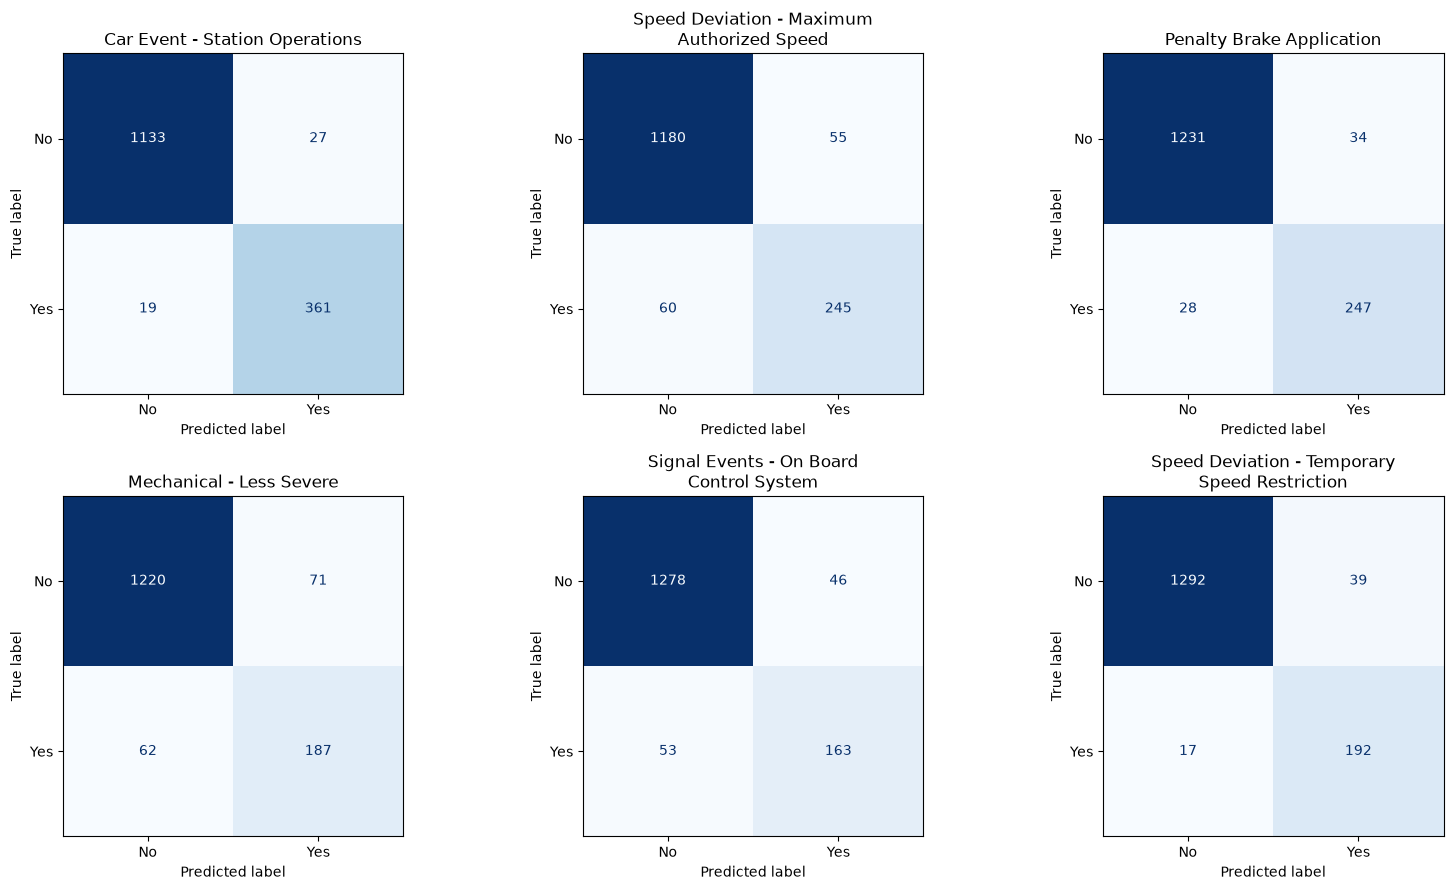

In [17]:
import matplotlib.pyplot as plt
from sklearn.metrics import multilabel_confusion_matrix, ConfusionMatrixDisplay
from textwrap import fill

cm = multilabel_confusion_matrix(y_true, y_pred)

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for i, ax in enumerate(axes.flat):
    ConfusionMatrixDisplay(
        confusion_matrix=cm[i],
        display_labels=["No", "Yes"]
    ).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")

    ax.set_title(fill(TARGETS[target_names[i]].split(" / ")[-1], 30))

plt.tight_layout()
plt.show()

In [18]:
results.to_csv(results_dir / f"seed_{SEED}.csv", index=False)

summary = summary_markdown(
    f"{results_dir.name}: frozen FT-Transformer and BERT, two-tower join",
    [
        "Both encoders frozen. FT-Transformer CLS vector and BERT CLS vector, each projected to "
        f"{PROJECTION}, normalized, concatenated, then dropout and one linear layer with six outputs.",
        f"Seed {SEED}, batch {batch_size}, best epoch {best_epoch} (validation mean AP {best_ap:.3f}).",
        f"Encoders alone on validation: FT-Transformer mean AP {ft_val_ap:.3f}, BERT mean AP {bert_val_ap:.3f}.",
        f"Micro F1 {micro_f1:.3f}, macro F1 {macro_f1:.3f}.",
    ],
    results
)

(results_dir / "summary.md").write_text(summary, encoding="utf-8")

print(summary)
print("Summary to share:", results_dir / "summary.md")

# fusion_frozen: frozen FT-Transformer and BERT, two-tower join

- Both encoders frozen. FT-Transformer CLS vector and BERT CLS vector, each projected to 256, normalized, concatenated, then dropout and one linear layer with six outputs.
- Seed 42, batch 64, best epoch 8 (validation mean AP 0.866).
- Encoders alone on validation: FT-Transformer mean AP 0.607, BERT mean AP 0.868.
- Micro F1 0.845, macro F1 0.836.
- All numbers are test scores. Each event's yes/no cutoff was picked on validation.

## Average over the events

| Model | Average F1 | Mean AP |
|---|---|---|
| Fusion (frozen) | 0.836 | 0.894 |

## F1 per event

| Event | Fusion (frozen) |
|---|---|
| Station Ops | 0.940 |
| Speed - MAS | 0.810 |
| Emerg/Penalty Brake | 0.888 |
| Mechanical (less) | 0.738 |
| Signal - OBCS | 0.767 |
| Speed - TSR | 0.873 |
| Average | 0.836 |

## AP per event

| Event | Fusion (frozen) |
|---|---|
| Station Ops | 0.983 |
| Speed - MAS | 0.852 |
| Emerg/Penalty Brake | 0.937 |
| Mechanical (les

In [19]:
# One table: tabular only, text only, fused (test scores)
rows = {}

for name, table in [
    ("Tabular only", pd.read_csv(TABULAR_RESULTS)),
    ("Text only", pd.read_csv(TEXT_RESULTS)),
    ("Fused", results)
]:
    assert table["label"].tolist() == target_names
    rows[name] = dict(
        **{f"AP {label}": value for label, value in zip(table["label"], table["ap"])},
        **{"Mean AP": table["ap"].mean(), "Macro F1": table["f1"].mean()}
    )

comparison = pd.DataFrame(rows).T

print(comparison.round(3).to_string())

              AP Station Ops  AP Speed - MAS  AP Emerg/Penalty Brake  AP Mechanical (less)  AP Signal - OBCS  AP Speed - TSR  Mean AP  Macro F1
Tabular only           0.957           0.545                   0.564                 0.634             0.638           0.544    0.647     0.629
Text only              0.982           0.872                   0.934                 0.782             0.851           0.930    0.892     0.836
Fused                  0.983           0.852                   0.937                 0.813             0.858           0.917    0.894     0.836
